# Forecasting daily closes with a two-stage model

**Instruments** NIFTY 50 (`^NSEI`) and TCS (`TCS.NS`) &nbsp;&nbsp;|&nbsp;&nbsp; **Window** 29 Jan 2015 – 29 Jan 2025 &nbsp;&nbsp;|&nbsp;&nbsp; **Split** 80 / 20, chronological

A linear model and a neural one, stacked. ARIMA does the heavy lifting and produces the
one-day-ahead base forecast; whatever it gets wrong is passed to an LSTM in PyTorch, which reads
the last ten normalised residuals and predicts the next one. The two numbers are added together.

Ten years of daily closes come from yfinance. Nothing below ever looks forward: every forecast
in this notebook is one step ahead.

In [1]:
import copy
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import torch
import torch.nn as nn
import yfinance as yf
from matplotlib.collections import PolyCollection
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore", message="adfuller currently returns")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- run configuration ----
TICKERS = {"NIFTY 50": "^NSEI", "TCS": "TCS.NS"}
START, END = "2015-01-29", "2025-01-30"  # ten calendar years; END itself is not included
TRAIN_FRAC, D, WINDOW, BURN_IN, N_SEEDS = 0.8, 2, 10, 20, 5
DATA_DIR = Path("data")

# ---- house style: every figure below inherits this ----
PAPER, INK, RULE, BAND = "#fbfaf7", "#2f2b33", "#c6c0b6", "#9fc3bd"
PALETTE = ["#17706e", "#a4306a", "#c6881f", "#4d6475"]  # pine, mulberry, ochre, slate
plt.rcParams.update({
    "figure.figsize": (14, 4),
    "figure.facecolor": PAPER,
    "savefig.facecolor": PAPER,
    "axes.facecolor": PAPER,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.edgecolor": RULE,
    "axes.linewidth": 0.9,
    "axes.labelcolor": INK,
    "axes.labelsize": 9,
    "axes.titlelocation": "left",
    "axes.titlesize": 10.5,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.titlepad": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": RULE,
    "grid.alpha": 0.7,
    "grid.linestyle": ":",
    "grid.linewidth": 0.7,
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 9.5,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.frameon": False,
    "legend.fontsize": 8.5,
    "lines.linewidth": 1.3,
})

print(f"numpy {np.__version__} | pandas {pd.__version__} | statsmodels {statsmodels.__version__} | "
      f"torch {torch.__version__} | yfinance {yf.__version__}")

numpy 2.4.6 | pandas 3.0.6 | statsmodels 0.15.0 | torch 2.14.1+cpu | yfinance 1.7.0


---

## Getting the price history

Adjusted daily closes, pulled once per ticker and cached to CSV, so a rerun works from exactly
the same numbers rather than whatever Yahoo is serving that day.

In [2]:
def load_close(ticker):
    # One round trip per ticker; after that the CSV on disk is the source of truth
    DATA_DIR.mkdir(exist_ok=True)
    path = DATA_DIR / f"{ticker.lstrip('^')}_{START}_{END}.csv"
    if path.exists():
        close = pd.read_csv(path, index_col=0, parse_dates=True).squeeze("columns")
    else:
        close = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)["Close"].squeeze("columns")
        close.to_csv(path)
    return close.dropna().rename(ticker)


prices = {name: load_close(t) for name, t in TICKERS.items()}
pd.DataFrame({name: s.describe() for name, s in prices.items()}).round(2)

,NIFTY 50,TCS
count,2462.00,2469.00
mean,13627.47,2101.80
std,5027.87,1005.45
min,6970.60,828.28
25%,9514.41,1021.69
50%,11579.15,1811.41
75%,17604.80,2993.65
max,26216.05,4230.71


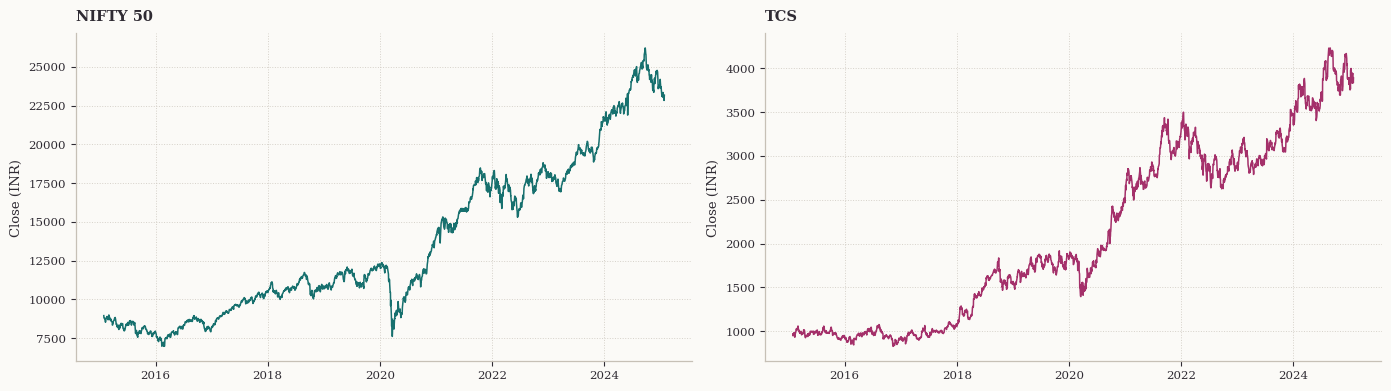

In [3]:
fig, axes = plt.subplots(1, 2)
for ax, color, (name, s) in zip(axes, PALETTE, prices.items()):
    ax.plot(s, color=color, lw=1.1)
    ax.set(title=name, ylabel="Close (INR)")
plt.tight_layout()
plt.show()

---

## Carving out a test period

The split is chronological rather than random — the earliest 80% of each series is all the model
ever trains on, and the final 20% stays sealed until evaluation.

In [4]:
split = {name: int(TRAIN_FRAC * len(s)) for name, s in prices.items()}
for name, s in prices.items():
    n = split[name]
    print(f"{name:8s} train {s.index[0].date()} -> {s.index[n - 1].date()} ({n} days) | "
          f"test {s.index[n].date()} -> {s.index[-1].date()} ({len(s) - n} days)")

NIFTY 50 train 2015-01-29 -> 2023-01-27 (1969 days) | test 2023-01-30 -> 2025-01-29 (493 days)
TCS      train 2015-01-29 -> 2023-01-25 (1975 days) | test 2023-01-27 -> 2025-01-29 (494 days)


---

## Is the series stationary?

ARIMA wants a stationary input, so before committing to a value for `d` we put the training
portion of each series through an Augmented Dickey–Fuller test three times over: at the level,
after one difference, and after two.

In [5]:
def adf_p(x):
    return adfuller(x.dropna(), autolag="AIC")[1]


pd.DataFrame({name: {"level": adf_p(s.iloc[:split[name]]),
                     "1st difference": adf_p(s.iloc[:split[name]].diff()),
                     "2nd difference": adf_p(s.iloc[:split[name]].diff().diff())}
              for name, s in prices.items()}).T.round(4).rename_axis("ADF p-value")

,level,1st difference,2nd difference
ADF p-value,,,
NIFTY 50,0.9275,0.0,0.0
TCS,0.9337,0.0,0.0


> **Verdict.** At their levels both series are nowhere near stationary — p ≈ 0.93, so the unit
> root stands. One difference is already enough to clear it, and a second clears it outright
> (p ≈ 0). We go with `d = 2`.

---

## Choosing the orders from the correlograms

Twenty lags of each, computed on the training portion of the twice-differenced series.

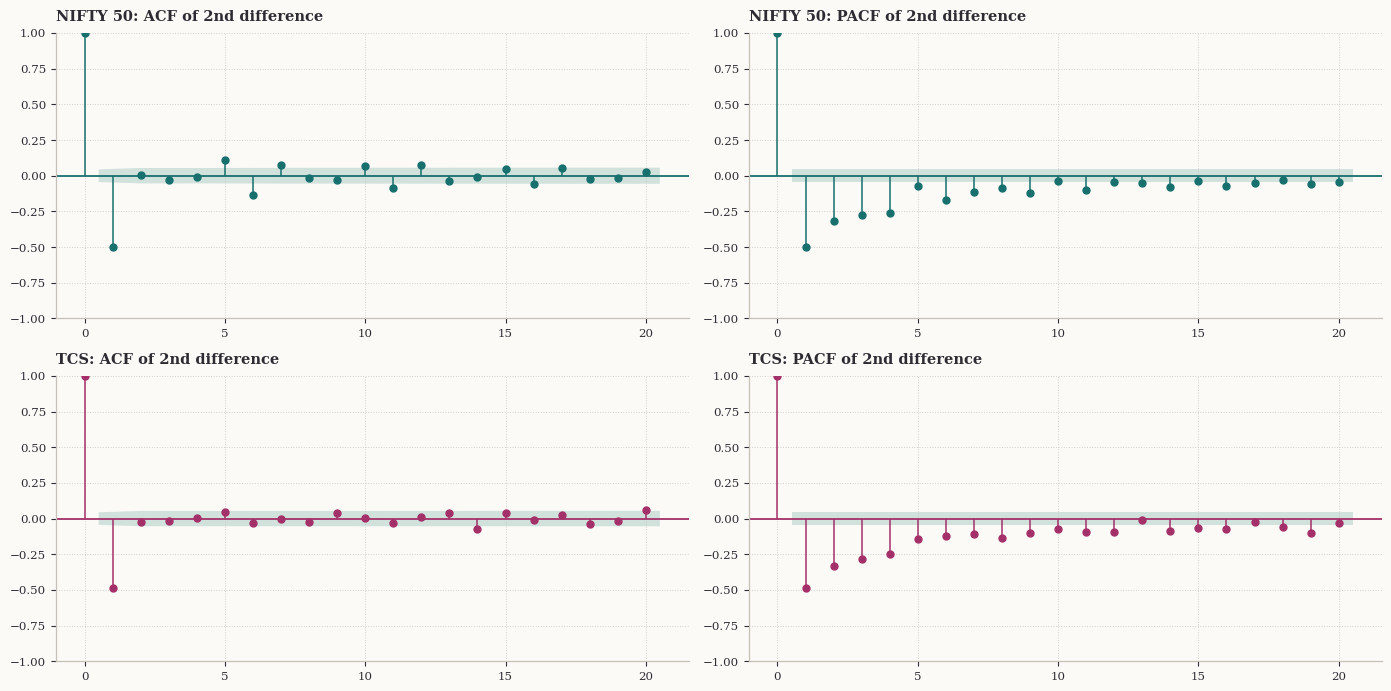

lag 1  lag 2  lag 3  lag 4  lag 5
NIFTY 50 ACF  -0.496  0.005 -0.030 -0.010  0.111
         PACF -0.496 -0.320 -0.273 -0.263 -0.075
TCS      ACF  -0.485 -0.022 -0.016  0.007  0.050
         PACF -0.485 -0.336 -0.284 -0.247 -0.146

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
lags = {}
for row, color, (name, s) in zip(axes, PALETTE, prices.items()):
    x = s.iloc[:split[name]].diff().diff().dropna()
    stem = {"colors": color, "linewidth": 1.1}
    plot_acf(x, lags=20, ax=row[0], title=f"{name}: ACF of 2nd difference",
             color=color, vlines_kwargs=stem)
    plot_pacf(x, lags=20, ax=row[1], title=f"{name}: PACF of 2nd difference", method="ywm",
              color=color, vlines_kwargs=stem)
    for ax in row:  # statsmodels ships its own band colour; bring it into line
        for patch in ax.collections:
            if isinstance(patch, PolyCollection):
                patch.set(facecolor=BAND, edgecolor="none", alpha=0.45)
    lags[name, "ACF"] = acf(x, nlags=5)[1:]
    lags[name, "PACF"] = pacf(x, nlags=5, method="ywm")[1:]
plt.tight_layout()
plt.show()
pd.DataFrame(lags, index=[f"lag {k}" for k in range(1, 6)]).T.round(3)

Both tickers tell the same story. The ACF drops to a single heavy negative spike at lag 1 —
somewhere around −0.5 — and has nothing meaningful to say after it. The PACF does the opposite
and tails away gradually instead of cutting off.

That asymmetry is the textbook MA(1) fingerprint: `q = 1`, `p = 0`. Together with `d = 2` the
specification is **ARIMA(0,2,1)**, and the same one serves both series.

---

## Stage one · ARIMA(0,2,1)

Fitted once on the training set, after which the coefficients are frozen. The frozen model then
walks forward across the whole series and emits a one-step-ahead forecast for every day, so each
prediction is assembled only from closes up to the previous session.

In [7]:
ORDER = (0, D, 1)  # p and q come straight off the correlograms
y = {name: pd.Series(s.to_numpy()) for name, s in prices.items()}  # plain 0..n index; the trading calendar has gaps
fits, onestep, resid = {}, {}, {}
for name in prices:
    n = split[name]
    res = ARIMA(y[name].iloc[:n], order=ORDER).fit()
    pred = res.apply(y[name]).predict()  # coefficients stay fixed, forecast advances one day at a time
    fits[name], onestep[name] = res, pred.to_numpy()
    resid[name] = (y[name] - pred).to_numpy()

pd.DataFrame({name: fits[name].params for name in prices}).round(3).rename_axis(f"ARIMA{ORDER}")

,NIFTY 50,TCS
"ARIMA(0, 2, 1)",,
ma.L1,-0.999,-1.000
sigma2,16088.890,840.696


> **Note on θ.** Both fits land on `ma.L1` ≈ −1. An MA coefficient that close to −1 very nearly
> undoes the second difference, which is why the one-step forecast ends up behaving like a random
> walk carrying a slowly updated drift rather than anything more ambitious.

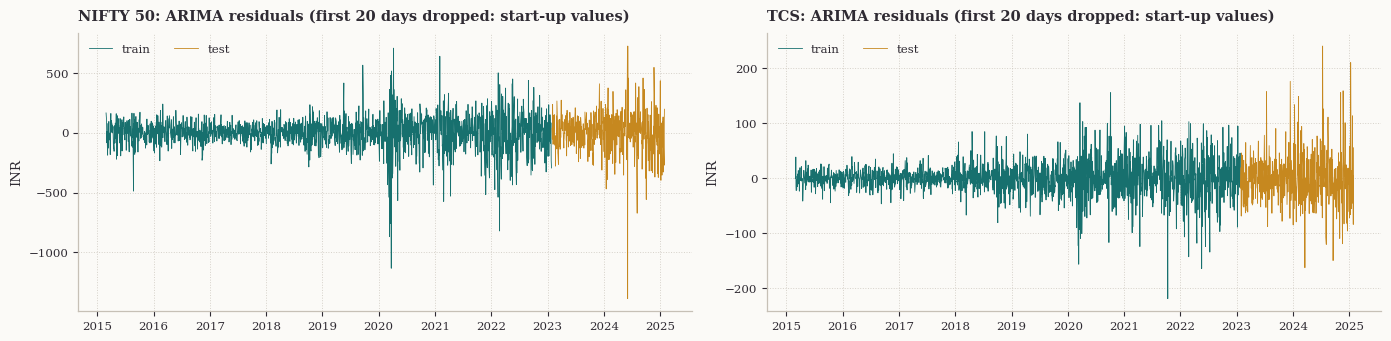

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (name, s) in zip(axes, prices.items()):
    n = split[name]
    ax.plot(s.index[BURN_IN:n], resid[name][BURN_IN:n], lw=0.6, color=PALETTE[0], label="train")
    ax.plot(s.index[n:], resid[name][n:], lw=0.6, color=PALETTE[2], label="test")
    ax.set(title=f"{name}: ARIMA residuals (first {BURN_IN} days dropped: start-up values)", ylabel="INR")
    ax.legend(ncol=2)
plt.tight_layout()
plt.show()

---

## Stage two · an LSTM on the residuals

Whatever ARIMA could not explain is handed to a small recurrent network.

| | |
| :--- | :--- |
| **Scaling** | residuals z-scored against the mean and standard deviation of the *training* residuals |
| **Input** | the previous 10 residuals |
| **Target** | the next residual |
| **Fitting** | training-period residuals only; the last 15% of the training windows are held back for early stopping |
| **Averaging** | predictions are averaged over 5 seeds |

In [9]:
class ResidualLSTM(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):  # expects (batch, WINDOW, 1)
        out, _ = self.lstm(x)
        return self.head(out[:, -1]).squeeze(-1)


def to_tensor(a):
    return torch.tensor(np.asarray(a), dtype=torch.float32)


def train_lstm(X_tr, y_tr, X_va, y_va, seed, epochs=300, patience=20, lr=1e-3, batch_size=64):
    torch.manual_seed(seed)
    model = ResidualLSTM()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn, gen = nn.MSELoss(), torch.Generator().manual_seed(seed)
    X_tr, y_tr, X_va, y_va = map(to_tensor, (X_tr, y_tr, X_va, y_va))
    history, best, best_state, wait = [], np.inf, None, 0
    for _ in range(epochs):
        model.train()
        total = 0.0
        for idx in torch.randperm(len(X_tr), generator=gen).split(batch_size):
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(X_va), y_va).item()
        history.append((total / len(X_tr), val))
        if val < best - 1e-5:
            best, best_state, wait = val, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model.eval(), np.array(history)


def predict(model, X):
    with torch.no_grad():
        return model(to_tensor(X)).numpy()


print(ResidualLSTM())
print("trainable parameters:", sum(p.numel() for p in ResidualLSTM().parameters()))

ResidualLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=1, bias=True)
)
trainable parameters: 4513


In [10]:
# one network per seed, per ticker; the averaged prediction is the ARIMA correction
correction = {}
for name in prices:
    n, N = split[name], len(y[name])
    e = resid[name]
    mu, sd = e[BURN_IN:n].mean(), e[BURN_IN:n].std()
    z = (e - mu) / sd
    days = np.arange(BURN_IN + WINDOW, N)                        # each day is read off the ten residuals that precede it
    X = np.stack([z[d - WINDOW:d] for d in days])[..., None]
    target = z[days]
    train_pos = np.where(days < n)[0]
    n_val = int(0.15 * len(train_pos))
    tr, va, te = train_pos[:-n_val], train_pos[-n_val:], np.where(days >= n)[0]

    models = [train_lstm(X[tr], target[tr], X[va], target[va], seed)[0] for seed in range(N_SEEDS)]
    correction[name] = np.mean([predict(m, X[te]) for m in models], axis=0) * sd + mu
    print(f"{name:8s} trained {N_SEEDS} LSTMs on {len(tr)} windows ({len(va)} held out for early stopping), "
          f"predicted {len(te)} test days")

NIFTY 50 trained 5 LSTMs on 1649 windows (290 held out for early stopping), predicted 493 test days


TCS      trained 5 LSTMs on 1654 windows (291 held out for early stopping), predicted 494 test days


---

## Results on the test set

The last 60 trading days of the test period, with the actual close plotted against the ARIMA
baseline and against the residual-corrected hybrid. Every point is a one-day-ahead forecast.

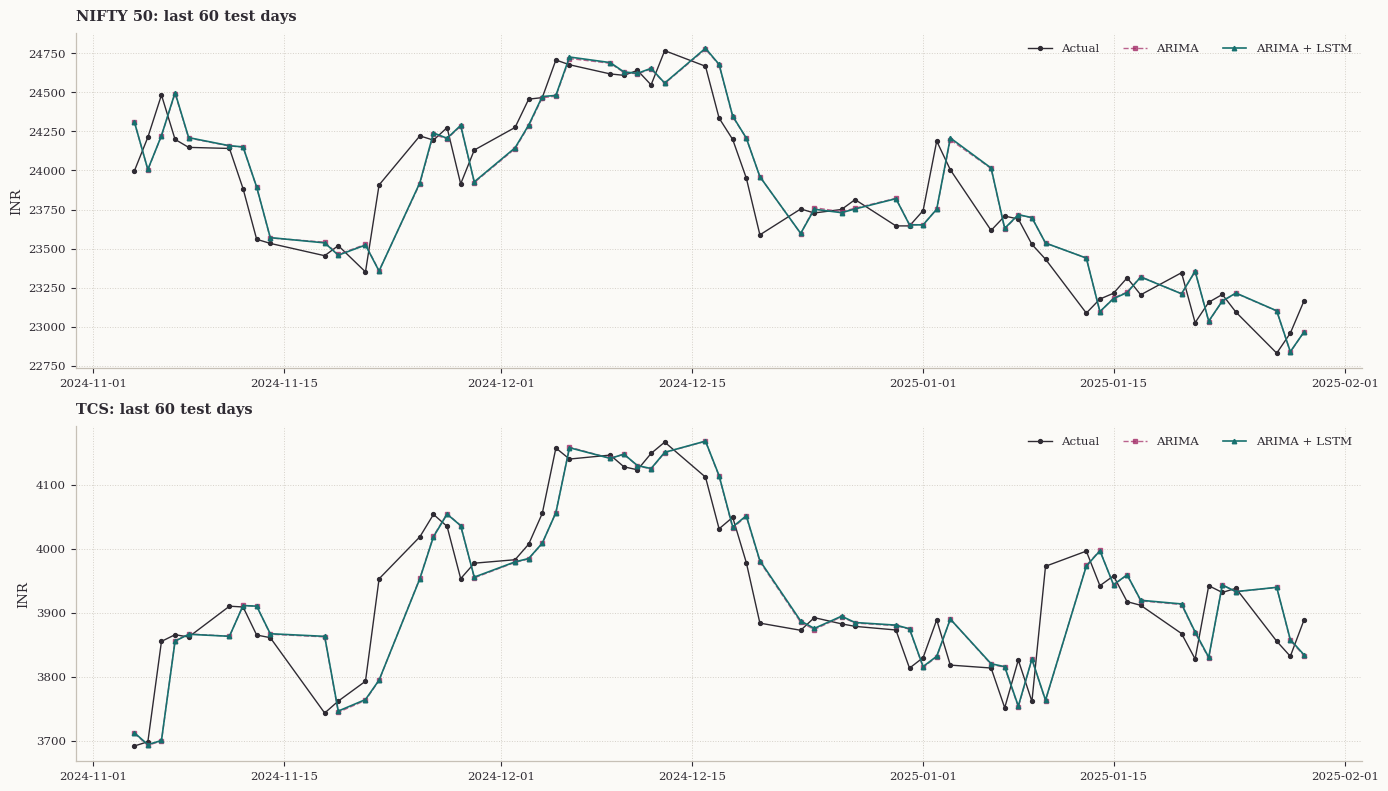

In [11]:
# baseline vs. baseline + learned residual, side by side
forecasts = {}
for name, s in prices.items():
    n = split[name]
    arima = onestep[name][n:]
    forecasts[name] = {f"ARIMA{ORDER} (baseline)": arima,
                       "ARIMA + LSTM (hybrid)": arima + correction[name]}

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (name, s) in zip(axes, prices.items()):
    n, last = split[name], slice(-60, None)
    dates = s.index[n:][last]
    ax.plot(dates, s.to_numpy()[n:][last], "o-", ms=2.8, lw=1.0, color=INK, label="Actual")
    ax.plot(dates, forecasts[name][f"ARIMA{ORDER} (baseline)"][last], "s--", ms=2.8, lw=1.0,
            color=PALETTE[1], alpha=0.75, label="ARIMA")
    ax.plot(dates, forecasts[name]["ARIMA + LSTM (hybrid)"][last], "^-", ms=3.2, lw=1.2,
            color=PALETTE[0], label="ARIMA + LSTM")
    ax.set(title=f"{name}: last 60 test days", ylabel="INR")
    ax.legend(ncol=3)
plt.tight_layout()
plt.show()